# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
from aitlas.datasets import MSTAR8Dataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [4]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/MSTAR-8/",
    "csv_file": "/home/dragik/data/FAIR_EO/MSTAR-8/train.csv",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = MSTAR8Dataset(dataset_config)

## Show images from the dataset

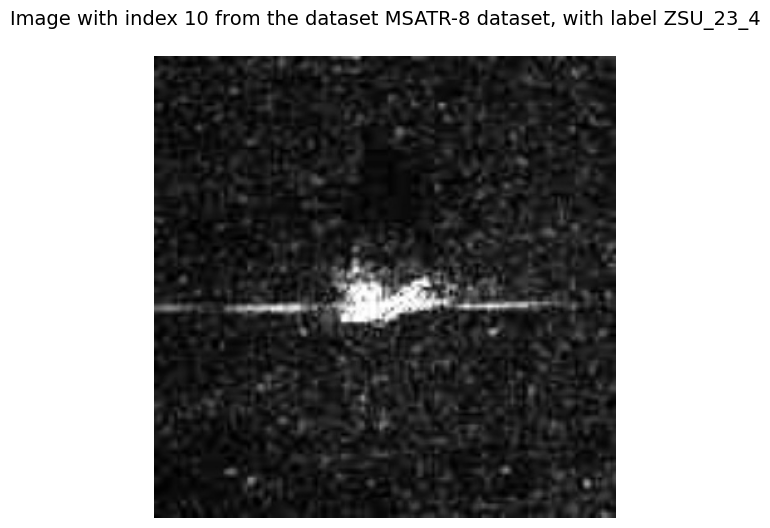

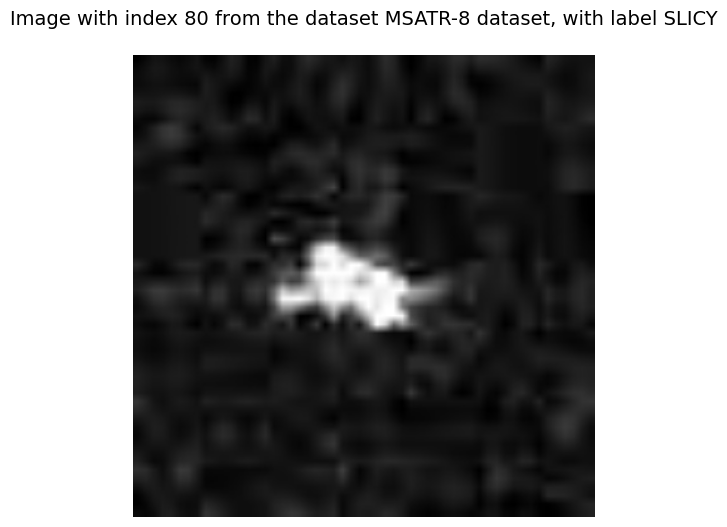

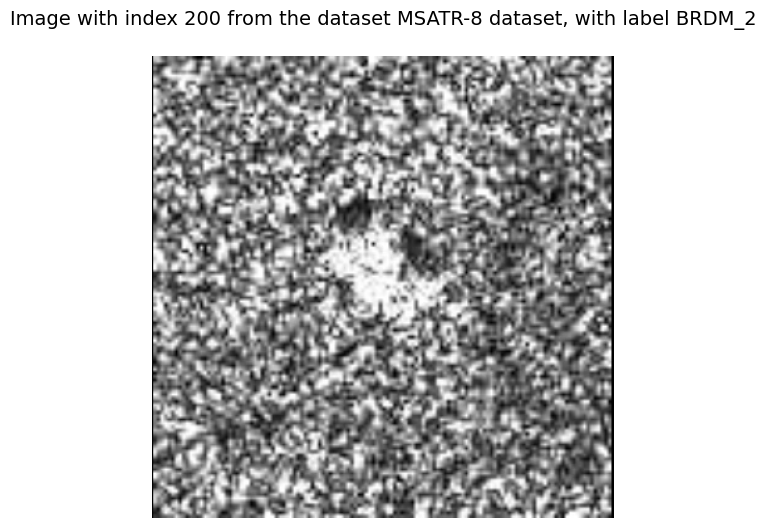

In [5]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(200)

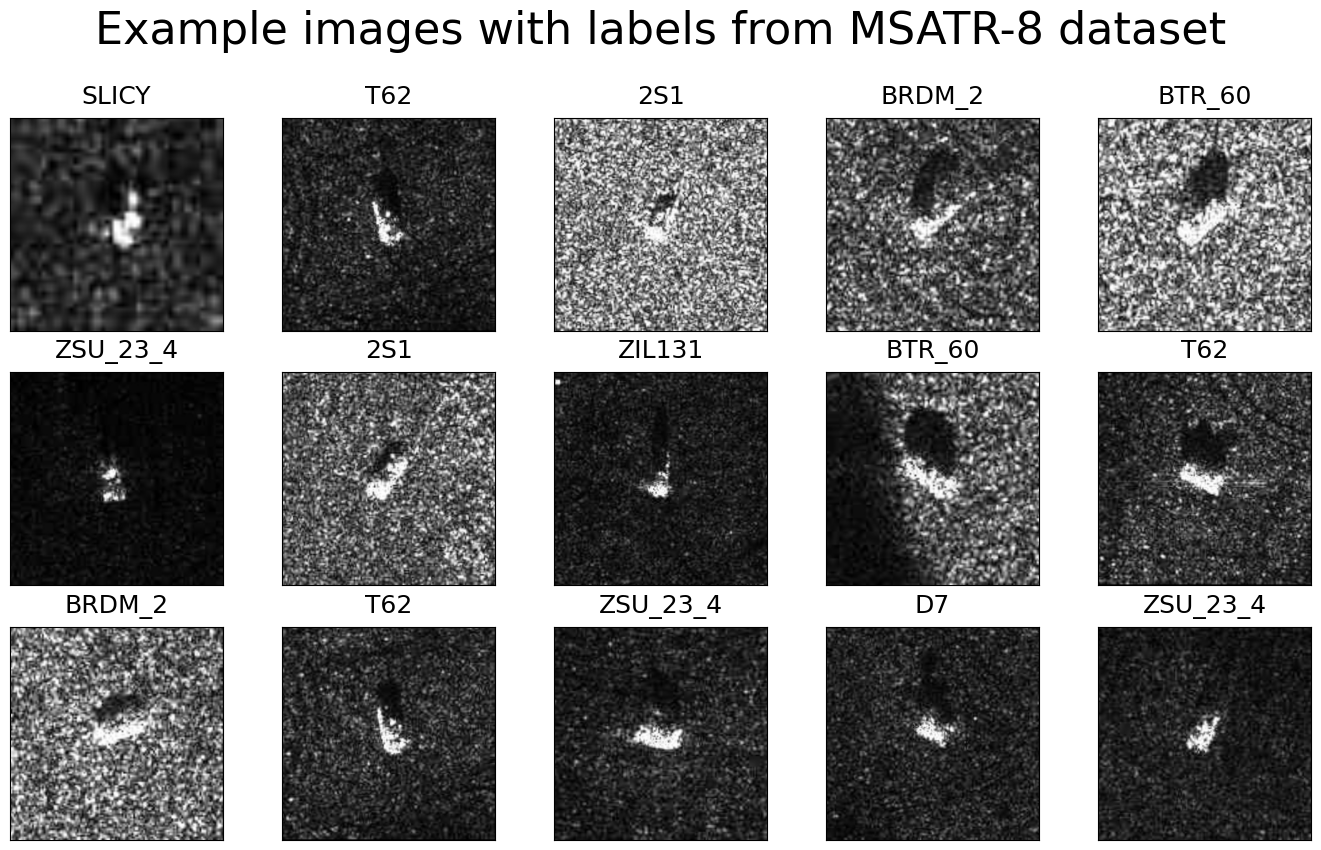

In [6]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [7]:
dataset.show_samples()

,File name,Label
0,BRDM_2/HB15987.JPG,BRDM_2
1,SLICY/HB14965.JPG,SLICY
2,BRDM_2/HB15166.JPG,BRDM_2
3,BRDM_2/HB17377.JPG,BRDM_2
4,D7/HB15017.JPG,D7
5,BRDM_2/HB15242.JPG,BRDM_2
6,T62/HB20010.JPG,T62
7,SLICY/HB15452.JPG,SLICY
8,T62/HB19979 (copy).JPG,T62
9,BTR_60/HB03865.JPG,BTR_60


In [8]:
dataset.data_distribution_table()

,Label,Count
0,2S1,946
1,BRDM_2,1123
2,BTR_60,1081
3,D7,449
4,SLICY,1042
5,T62,909
6,ZIL131,904
7,ZSU_23_4,1120


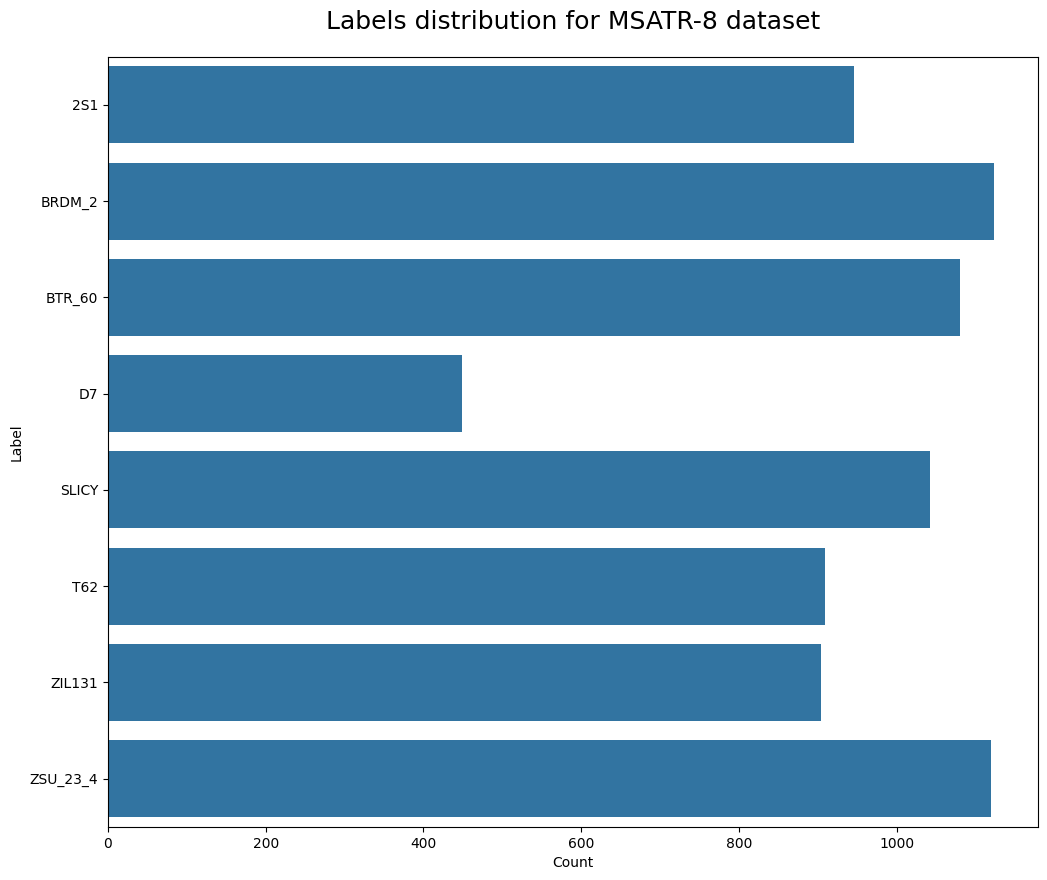

In [9]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [4]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/MSTAR-8/",
    "csv_file": "/home/dragik/data/FAIR_EO/MSTAR-8/train.csv",
}

train_dataset = MSTAR8Dataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/MSTAR-8/",
    "csv_file": "/home/dragik/data/FAIR_EO/MSTAR-8/val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = MSTAR8Dataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(7574, 946)

## Setup and create the model for training

In [5]:
epochs = 50
model_directory = "/home/dragik/data/FAIR_EO/experiments/MSTAR-8/"
model_config = {
    "num_classes": 8, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-13 06:50:34,853 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-13 06:50:35,032 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [6]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-13 06:50:36,977 INFO Starting training.
training: 100%|██████████| 237/237 [01:19<00:00,  2.97it/s]
2025-05-13 06:51:56,797 INFO epoch: 1, time: 79, loss:  0.35256
testing on train set: 100%|██████████| 237/237 [00:48<00:00,  4.84it/s]
2025-05-13 06:52:48,372 INFO Accuracy:0.9259308159493003, Precision Micro:0.9259308159493003, Precision Macro:0.9430881431364095, Precision Weighted:0.9367196234558129, Precision per Class:[0.99555556 0.79538905 1.         0.98861048 1.         0.90338645
 0.98862344 0.87314017], Recall Micro:0.9259308159493003, Recall Macro:0.9274284107452031, Recall Weighted:0.9259308159493002, Recall per Class:[0.71035941 0.98308103 0.80573543 0.96659243 0.99904031 0.99779978
 0.96128319 0.99553571], F1_score Micro:0.9259308159492997, F1_score Macro:0.9289005307457783, F1_score Weighted:0.924483362280085, F1_score per Class:[0.82911783 0.87933094 0.89241803 0.97747748 0.99951992 0.94824882
 0.97476164 0.93032958]
testing on validation set: 100%|██████████| 30/

0.00013624834815412586

## Test the model

In [7]:

test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/MSTAR-8/",
    "csv_file": "/home/dragik/data/FAIR_EO/MSTAR-8/test.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = MSTAR8Dataset(test_dataset_config)
model_path = "/home/dragik/data/FAIR_EO/experiments/MSTAR-8/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-05-13 09:34:09,602 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/MSTAR-8/checkpoint.pth.tar
2025-05-13 09:34:10,452 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/MSTAR-8/checkpoint.pth.tar at epoch 51
testing on test set: 100%|██████████| 60/60 [00:07<00:00,  8.17it/s]


[{'Accuracy': 0.9989429175475687},
 {'Precision Micro': 0.9989429175475687,
  'Precision Macro': 0.9989130434782609,
  'Precision Weighted': 0.9989521095688941,
  'Precision per Class': array([0.99130435, 1.        , 1.        , 1.        , 1.        ,
         1.        , 1.        , 1.        ])},
 {'Recall Micro': 0.9989429175475687,
  'Recall Macro': 0.9990458015267176,
  'Recall Weighted': 0.9989429175475686,
  'Recall per Class': array([1.        , 1.        , 1.        , 1.        , 1.        ,
         1.        , 1.        , 0.99236641])},
 {'F1_score Micro': 0.9989429175475681,
  'F1_score Macro': 0.9989752212685501,
  'F1_score Weighted': 0.998943200525688,
  'F1_score per Class': array([0.99563319, 1.        , 1.        , 1.        , 1.        ,
         1.        , 1.        , 0.99616858])}]

## Predictions

2025-05-13 09:34:21,126 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/MSTAR-8/checkpoint.pth.tar
2025-05-13 09:34:21,964 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/MSTAR-8/checkpoint.pth.tar at epoch 51


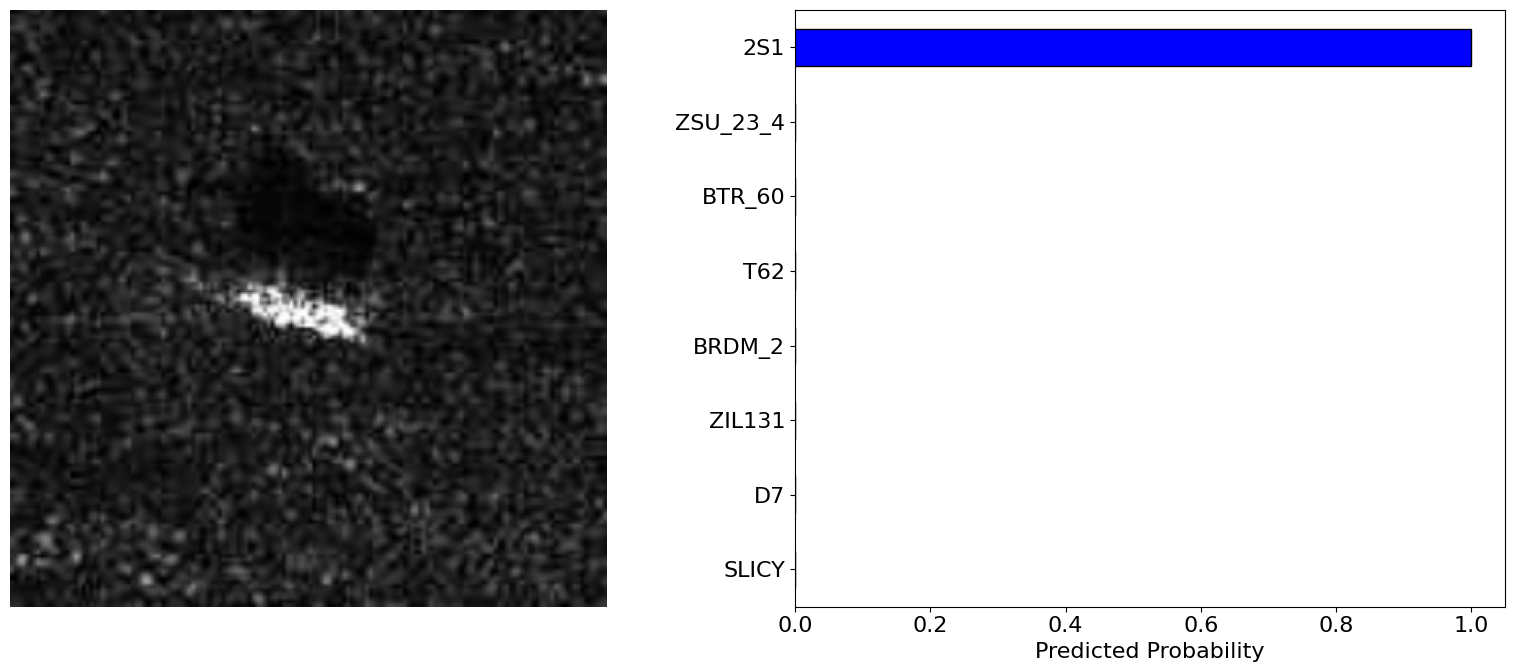

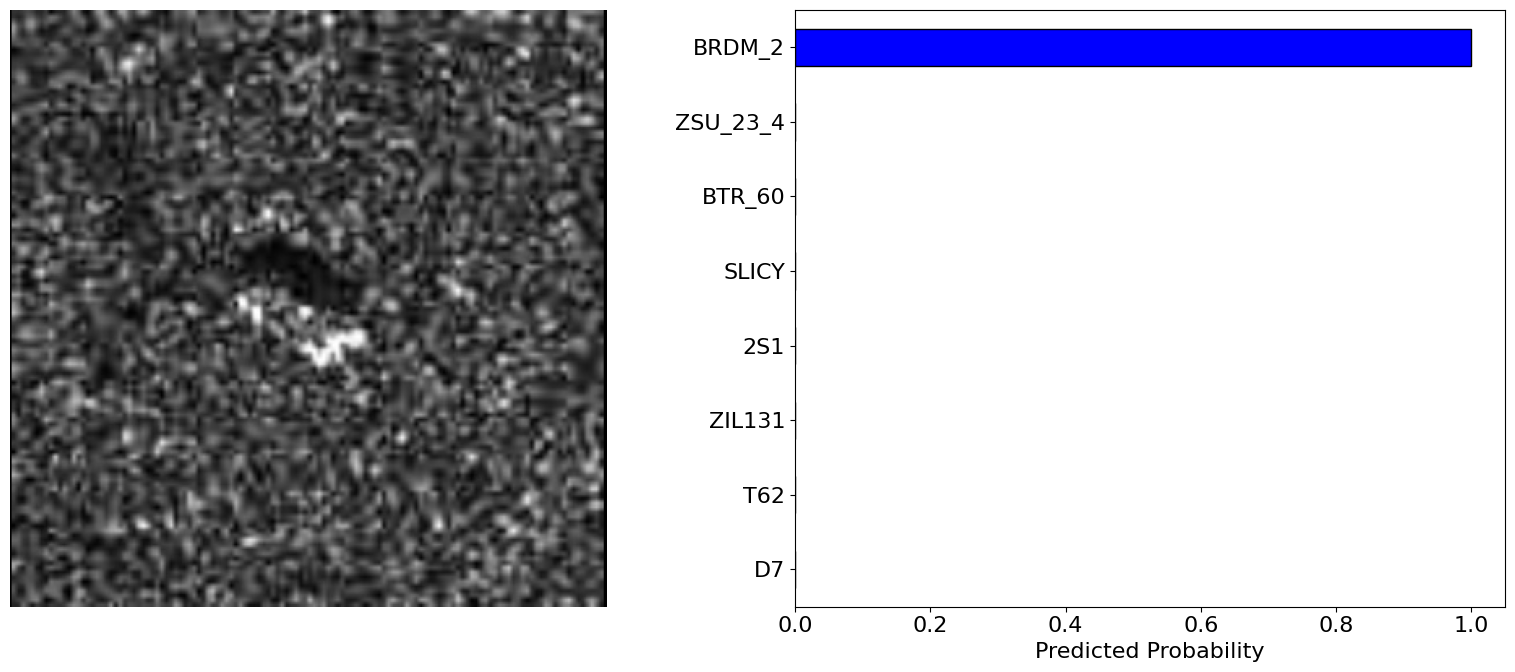

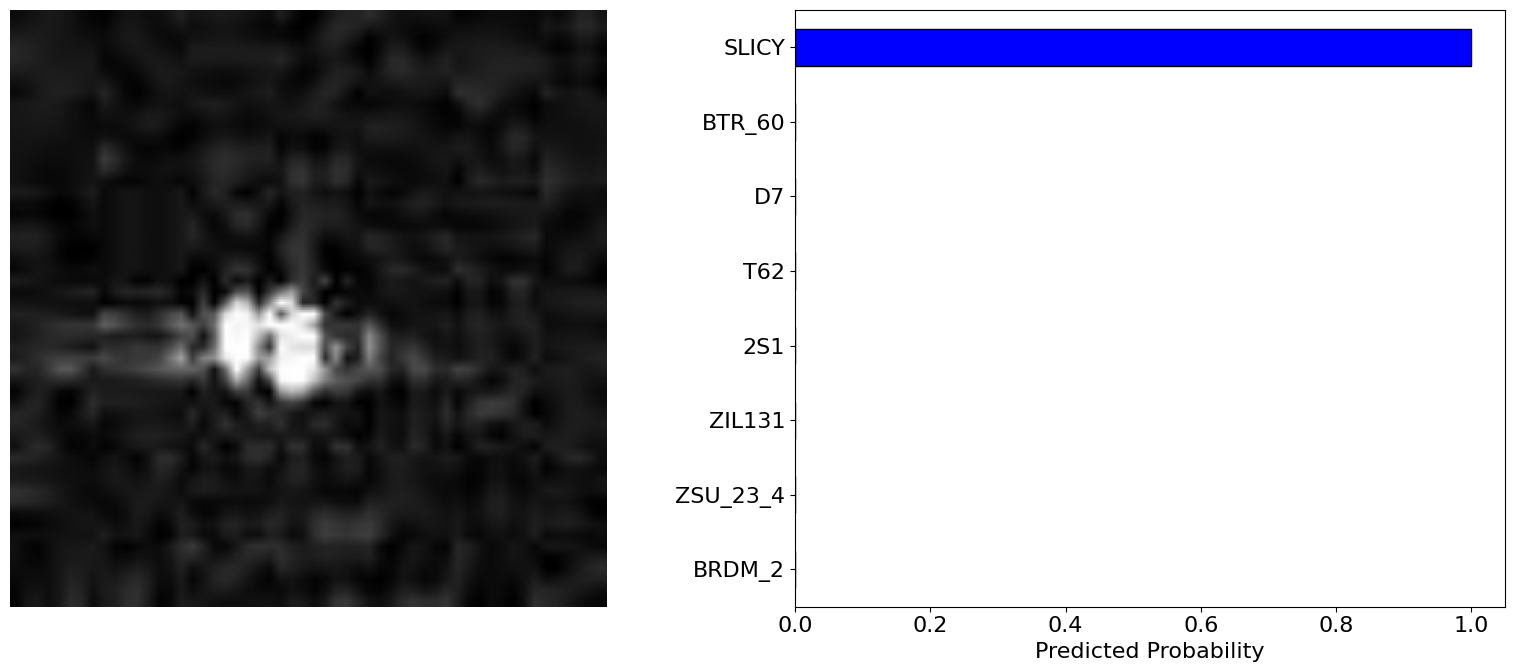

In [8]:
labels = ["2S1","BRDM_2","BTR_60","D7","SLICY","T62","ZIL131","ZSU_23_4"]
transform = ResizeCenterCropToTensor()

model_path = "/home/dragik/data/FAIR_EO/experiments/MSTAR-8/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/MSTAR-8/2S1/HB19977.JPG')
fig = model.predict_image(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/MSTAR-8/BRDM_2/HB17186.JPG')
fig = model.predict_image(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/MSTAR-8/SLICY/HB19094.JPG')
fig = model.predict_image(image, labels, transform)